# PS05-AI · Notebook sinh viên — Bài 27–28
**Nguyễn Bích Vân — IAI-UET-VNU**

**Bắt đầu:** chạy `00_Simulation_Template.ipynb` để học cú pháp trên ví dụ riêng, rồi trở lại notebook này.

Bạn chỉ cần tự điền **bốn vị trí `None` trong hai ô `CONFIG27` và `CONFIG28`**, chạy lại các ô, và viết nhận xét ở các chỗ trống. Bản này không điền sẵn đáp án hoặc kết luận.

**Run All khi chưa điền `None` không báo lỗi:** chương trình sẽ nhắc phần chưa làm, không tạo bảng CSV rỗng và không tự đoán đáp án thay bạn. Chạy hết notebook chưa có nghĩa là đã hoàn thành bài.


## 0. Mở và chạy trong VS Code

Chọn **Select Kernel → môi trường Python** ở góc trên bên phải. Chạy từng ô bằng nút ▶ hoặc **Shift+Enter**. Kết quả nằm **ngay dưới ô mã**, không ở Terminal.

Chỉ khi thiếu thư viện: bỏ dấu `#` trước `%pip` trong ô kế tiếp, chạy ô đó, sau đó **Restart Kernel** và chạy lại từ đầu. Không cần cài lại ở mỗi buổi. Không dán dấu nhắc `PS ...>` hay `>>` vào ô mã.

Notebook không đọc CSV đầu vào. Mọi dữ liệu được mô phỏng từ tham số đã nêu. Sau khi cài đủ thư viện, có thể chạy không cần Internet.


In [33]:
# Chỉ bỏ dấu # và chạy dòng sau nếu môi trường đang thiếu thư viện.
# %pip install numpy pandas plotnine ipykernel


In [34]:
from pathlib import Path
import sys

try:
    import numpy as np
    import pandas as pd
    import plotnine
    from plotnine import (
        ggplot, aes, geom_col, geom_point, geom_line,
        geom_hline, labs, scale_x_continuous, scale_x_log10,
    )
    from IPython.display import display
except ImportError as exc:
    raise ImportError(
        "Thiếu thư viện. Chạy ô %pip ở phía trên bằng chính kernel này, "
        "rồi Restart Kernel và chạy lại. Chi tiết: " + str(exc)
    ) from exc

OUTPUT_DIR = Path.cwd() / "ps05_27_28_outputs" / "student"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Python đang dùng:", sys.executable)
print("Phiên bản:", sys.version.split()[0])
print("NumPy:", np.__version__, "| pandas:", pd.__version__, "| plotnine:", plotnine.__version__)
print("Kết quả sẽ lưu tại:", OUTPUT_DIR.resolve())


Python đang dùng: c:\Users\admin\AppData\Local\Programs\Python\Python313\python.exe
Phiên bản: 3.13.7
NumPy: 2.3.5 | pandas: 3.0.3 | plotnine: 0.15.3
Kết quả sẽ lưu tại: C:\Users\admin\OneDrive\Documents\UET_2026_2027\MATH1052\MATH1052\PS05\PS05_AI_Student_A4_Notebooks\ps05_27_28_outputs\student


## Bài 27 — Sửa một mô phỏng chọn sai không gian mẫu

Hai agent chọn độc lập số lượt gọi công cụ trong $\{1,2,3,4\}$, mỗi giá trị đồng khả năng. Ta muốn mô phỏng **tổng** số lượt của hai agent. Một bạn viết:

```python
import numpy as np
rng = np.random.default_rng(2026)
total_values = np.arange(2, 9)
rng.choice(total_values)
```

**a)** Đoạn mã có mô phỏng đúng phép thử không? Giải thích bằng cách so sánh số cặp tạo ra tổng 2 và tổng 5.  
**b)** Sửa mã để mô phỏng đúng nhiều lần. Nêu ý nghĩa của mỗi hàng trong mảng kết quả và chiều cộng cần dùng.

Đây là nguyên nội dung Bài 27 của bộ đề PS05-AI A4, không phải bài hai xúc xắc sáu mặt trong bản gốc trước khi chuyển bối cảnh.


### 27a. Viết lập luận trước khi chạy

Nhấp đúp ô Markdown bên dưới để viết, rồi nhấn Shift+Enter để hiển thị.zz


**Bài làm 27a — sinh viên điền**

- Các cặp có thứ tự tạo ra tổng 2: (1,1)
- Các cặp có thứ tự tạo ra tổng 5: (1,4);(4,1);(2,3);(3,2)
- Cơ chế `rng.choice(total_values)` đang chọn đều những đối tượng nào? $\to$ Coi xác suất xuất hiện của các total_value là như nhau.
- Vì sao cách này phù hợp hoặc không phù hợp với phép thử hai agent? Cách này không phù hợp với phép thử hai agent vì đang coi xác suất xuất hiện các tổng là như nhau mặc dù tính tay thực tế khác nhau (vd như tổng 2 chỉ có 1 cặp, trong khi tổng 5 xuất hiện 4 cặp)


### 27b. Điền hai lựa chọn lập trình

`low` là giá trị nhỏ nhất có thể chọn. `high_exclusive` là đầu phải **không được sinh ra**. Với `size=(n_trials, 2)`, mỗi hàng có hai cột. Hãy chọn chiều cộng sao cho đầu ra có một tổng cho mỗi lượt thử.

Xem lại ô “hàng, cột và biến cố” trong notebook học mẫu nếu cần. `n_trials=100_000` là số lần mô phỏng gợi ý; đề không ấn định con số này.


In [35]:
CONFIG27 = {
    "seed": 2026,
    "n_trials": 100_000,
    "low": 1,
    "high_exclusive": 5,  # TODO: để sinh đủ các số 1, 2, 3, 4 thì đầu phải là gì?
    "sum_axis": 1,        # TODO: chọn 0 hay 1 theo ý nghĩa hàng/cột.
}


In [36]:
# Chạy lại ô này sau khi sửa CONFIG27.
choices27 = None
totals27 = None
table27 = None
plot27 = None

if CONFIG27["high_exclusive"] is None or CONFIG27["sum_axis"] is None:
    print("Bài 27: hãy điền hai vị trí None trong CONFIG27, rồi chạy lại từ ô cấu hình.")
else:
    n = CONFIG27["n_trials"]
    assert isinstance(n, int) and n > 0, "n_trials phải là số nguyên dương."
    assert CONFIG27["sum_axis"] in (0, 1), "Chiều cộng phải là 0 hoặc 1."
    rng27 = np.random.default_rng(CONFIG27["seed"])
    choices27 = rng27.integers(
        CONFIG27["low"], CONFIG27["high_exclusive"], size=(n, 2)
    )
    totals27 = choices27.sum(axis=CONFIG27["sum_axis"])
    print("Mảng lựa chọn:", choices27.shape, "| Dãy tổng:", totals27.shape)
    assert choices27.min() >= 1 and choices27.max() <= 4, "Kiểm tra lại miền lựa chọn của agent."
    assert totals27.shape == (n,), "Cần một tổng cho mỗi lượt thử; hãy xem lại chiều cộng."
    assert np.array_equal(totals27, choices27[:, 0] + choices27[:, 1]), "Tổng phải ghép hai lựa chọn trong cùng lượt."
    display(pd.DataFrame({
        "agent_a_calls": choices27[:8, 0],
        "agent_b_calls": choices27[:8, 1],
        "total_calls": totals27[:8],
    }))


Mảng lựa chọn: (100000, 2) | Dãy tổng: (100000,)


,agent_a_calls,agent_b_calls,total_calls
0,4,1,5
1,1,3,4
2,2,2,4
3,1,2,3
4,3,2,5
5,4,4,8
6,3,4,7
7,3,1,4


### 27b. Lập bảng và vẽ hình từ kết quả của bạn

Bảng giữ đủ các tổng 2 đến 8, kể cả tổng chưa xuất hiện trong mẫu. Phần này hỗ trợ đọc kết quả; hình không thay cho lời giải câu a.


In [37]:
if totals27 is None:
    print("Chưa lập bảng: hoàn thành CONFIG27 và chạy ô mô phỏng trước.")
else:
    support27 = np.arange(2, 9)
    counts27 = pd.Series(totals27).value_counts().reindex(support27, fill_value=0)
    table27 = pd.DataFrame({
        "total_calls": support27,
        "count": counts27.to_numpy(),
        "frequency": counts27.to_numpy() / len(totals27),
    })
    assert int(table27["count"].sum()) == len(totals27)
    assert np.isclose(table27["frequency"].sum(), 1)
    display(table27)
    print("Kiểm tra cấu trúc đã đạt. Vẫn cần giải thích cơ chế sinh mẫu bằng lời.")


,total_calls,count,frequency
0,2,6333,0.06333
1,3,12611,0.12611
2,4,18732,0.18732
3,5,24962,0.24962
4,6,18793,0.18793
5,7,12299,0.12299
6,8,6270,0.06270


Kiểm tra cấu trúc đã đạt. Vẫn cần giải thích cơ chế sinh mẫu bằng lời.


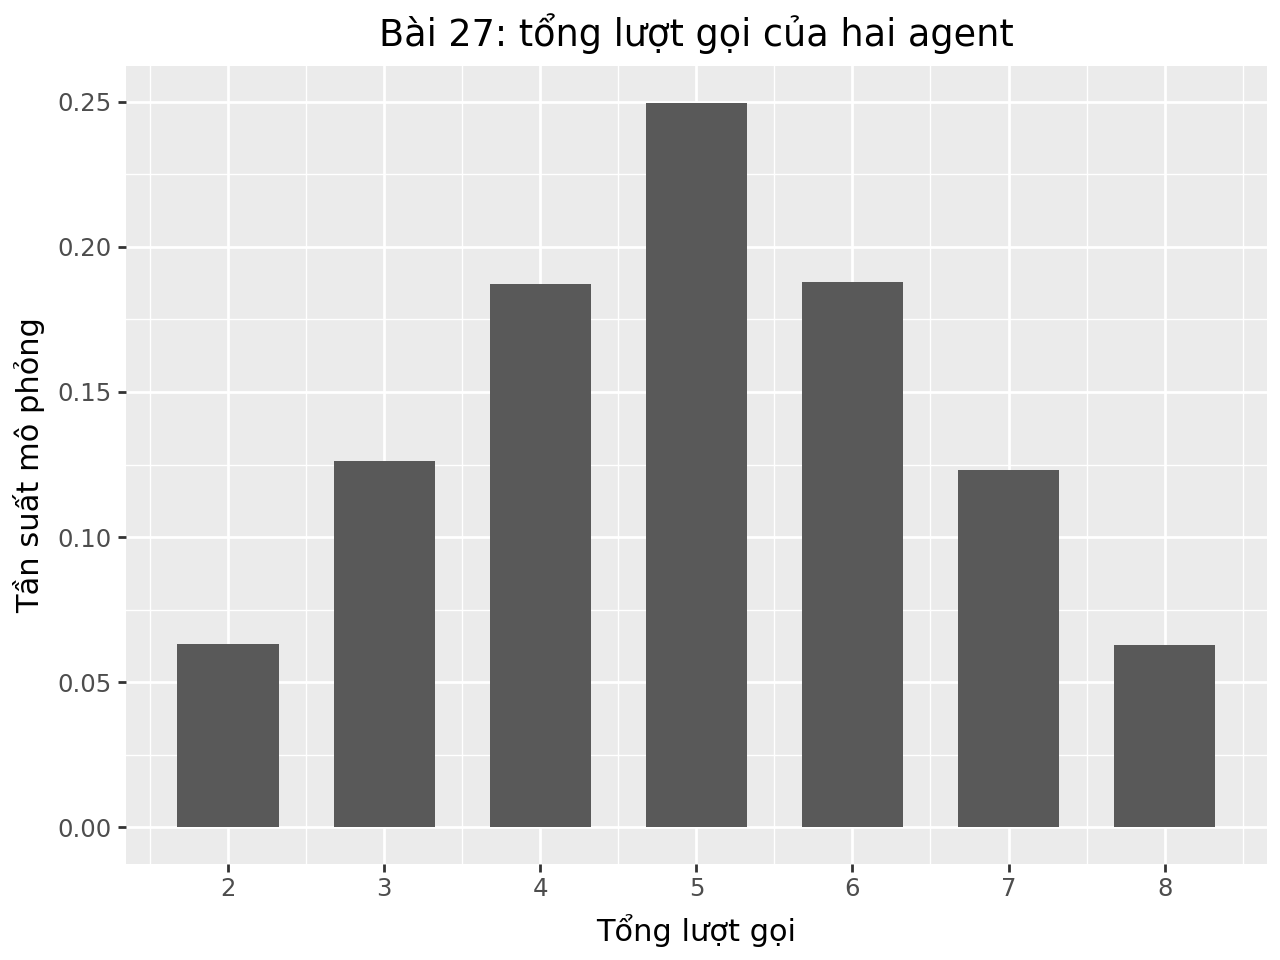

In [38]:
if table27 is None:
    print("Chưa vẽ: cần bảng tần suất của Bài 27.")
else:
    plot27 = (
        ggplot(table27, aes(x="total_calls", y="frequency"))
        + geom_col(width=0.65)
        + scale_x_continuous(breaks=table27["total_calls"].tolist())
        + labs(title="Bài 27: tổng lượt gọi của hai agent", x="Tổng lượt gọi", y="Tần suất mô phỏng")
    )
    display(plot27)


**Bài làm 27b — sinh viên điền**

- Một hàng trong `choices27` đại diện cho: một phép thử (cả 2 agent đều chọn độc lập một số)
- Tôi chọn chiều cộng là cột vì: Mỗi cột là kết quả chọn của từng agent.
- Khi dùng chiều cộng còn lại, đầu ra sẽ có ý nghĩa gì? $\to$ Tổng lượt gọi của từng agent.
- Bảng/hình mô phỏng có phù hợp với lập luận ở câu a không? Có, bảng mô phỏng củng cố được kết luận tỷ lệ xuất hiện của các tổng lượt gọi khác nhau là không đồng đều.


## Bài 28 — Theo dõi tần suất định tuyến khi số lượt tăng

Một bộ định tuyến giả lập chọn đều một trong **50 điểm xử lý có mã từ 0 đến 49**. Các lượt chọn độc lập. Gọi $A$ là biến cố mã được chọn **ít nhất bằng 35**. Dùng Python mô phỏng **100, 1.000 và 10.000** lượt chọn; có thể lấy ba tiền tố của cùng một dãy 10.000 lượt.

**a)** Tính $P(A)$ bằng cách đếm, trước khi chạy mã.  
**b)** Với từng cỡ mẫu, tạo dãy giá trị logic biểu thị $A$ và tính tần suất bằng trung bình của dãy đó.  
**c)** Lập bảng gồm cỡ mẫu, số lần $A$ xảy ra, tần suất và độ lệch tuyệt đối so với lý thuyết.  
**d)** Đổi seed và chạy lại. Sai lệch có bắt buộc giảm sau mỗi lần tăng cỡ mẫu không? Giải thích sự khác nhau giữa xác suất lý thuyết và tần suất mô phỏng.


### 28a. Đếm trước, mô phỏng sau

**Sinh viên điền:**

- Toàn bộ mã có thể chọn: `[0,49]`
- Các mã thuộc biến cố A: `[35,49]`
- Số kết quả thuận lợi / số kết quả có thể: 15 / 50 
- Xác suất lý thuyết: 0.3

### 28b–c. Sửa cấu hình rồi chạy

Trong ô tiếp theo, giữ các tham số đề cho. Chỉ điền `event_operator` và `p_theory`. Có thể viết một phân số Python ở `p_theory`, không cần tự làm tròn sớm.


In [39]:
CONFIG28 = {
    "seeds": [2026, 42],
    "endpoint_min": 0,
    "endpoint_max": 49,
    "threshold": 35,
    "sample_sizes": [100, 1_000, 10_000],
    "event_operator": ">=",  # TODO: điền một chuỗi như ">", ">=", "<", "<=", "==".
    "p_theory": 0.3,        # TODO: điền phân số/xác suất đã tự đếm ở câu a.
}


In [40]:
# Chỉ cần sửa CONFIG28, không phải viết lại vòng lặp.
table28 = None
plot28 = None
records28 = []
operators = {">=": np.greater_equal, ">": np.greater,
             "<=": np.less_equal, "<": np.less, "==": np.equal}

if CONFIG28["event_operator"] is None or CONFIG28["p_theory"] is None:
    print("Bài 28: hãy điền toán tử biến cố và xác suất lý thuyết trong CONFIG28.")
else:
    op = CONFIG28["event_operator"]
    p = CONFIG28["p_theory"]
    assert op in operators, "Chọn toán tử trong danh sách đã nêu."
    assert isinstance(p, (int, float)) and 0 <= p <= 1, "Xác suất phải thuộc [0,1]."
    sizes = CONFIG28["sample_sizes"]
    assert len(sizes) > 0 and all(isinstance(n, int) and n > 0 for n in sizes)
    assert CONFIG28["endpoint_min"] <= CONFIG28["endpoint_max"]
    assert len(CONFIG28["seeds"]) > 0, "Cần ít nhất một seed."
    for seed in CONFIG28["seeds"]:
        rng28 = np.random.default_rng(seed)
        endpoint_ids = rng28.integers(
            CONFIG28["endpoint_min"], CONFIG28["endpoint_max"] + 1,
            size=max(sizes),
        )
        for n in sizes:
            prefix = endpoint_ids[:n]
            flags = operators[op](prefix, CONFIG28["threshold"])
            count = int(flags.sum())
            frequency = float(flags.mean())
            records28.append({
                "seed": seed, "n_trials": n, "event_count": count,
                "frequency": frequency, "theoretical_probability": p,
                "absolute_error": abs(frequency - p),
            })
            assert np.isclose(frequency, count / n)
    table28 = pd.DataFrame(records28)
    display(table28)
    print("Bảng đã có dữ liệu. Hãy tự kiểm tra lại dấu bất đẳng thức và mẫu số lý thuyết.")


,seed,n_trials,event_count,frequency,theoretical_probability,absolute_error
0,2026,100,26,0.2600,0.3,0.0400
1,2026,1000,289,0.2890,0.3,0.0110
2,2026,10000,3001,0.3001,0.3,0.0001
3,42,100,34,0.3400,0.3,0.0400
4,42,1000,304,0.3040,0.3,0.0040
5,42,10000,2952,0.2952,0.3,0.0048


Bảng đã có dữ liệu. Hãy tự kiểm tra lại dấu bất đẳng thức và mẫu số lý thuyết.


### 28d. So sánh hai seed

Notebook đã chuẩn bị hai seed 2026 và 42; có thể thử thêm seed khác. Mỗi seed tạo một dãy riêng, rồi lấy các tiền tố. So sánh cột `absolute_error` theo **cùng một seed**, không trộn các dòng khác seed thành một dãy.

`>=` và `>` khác nhau tại đúng giá trị ngưỡng. Hãy kiểm tra câu chữ của đề trước khi điền toán tử.


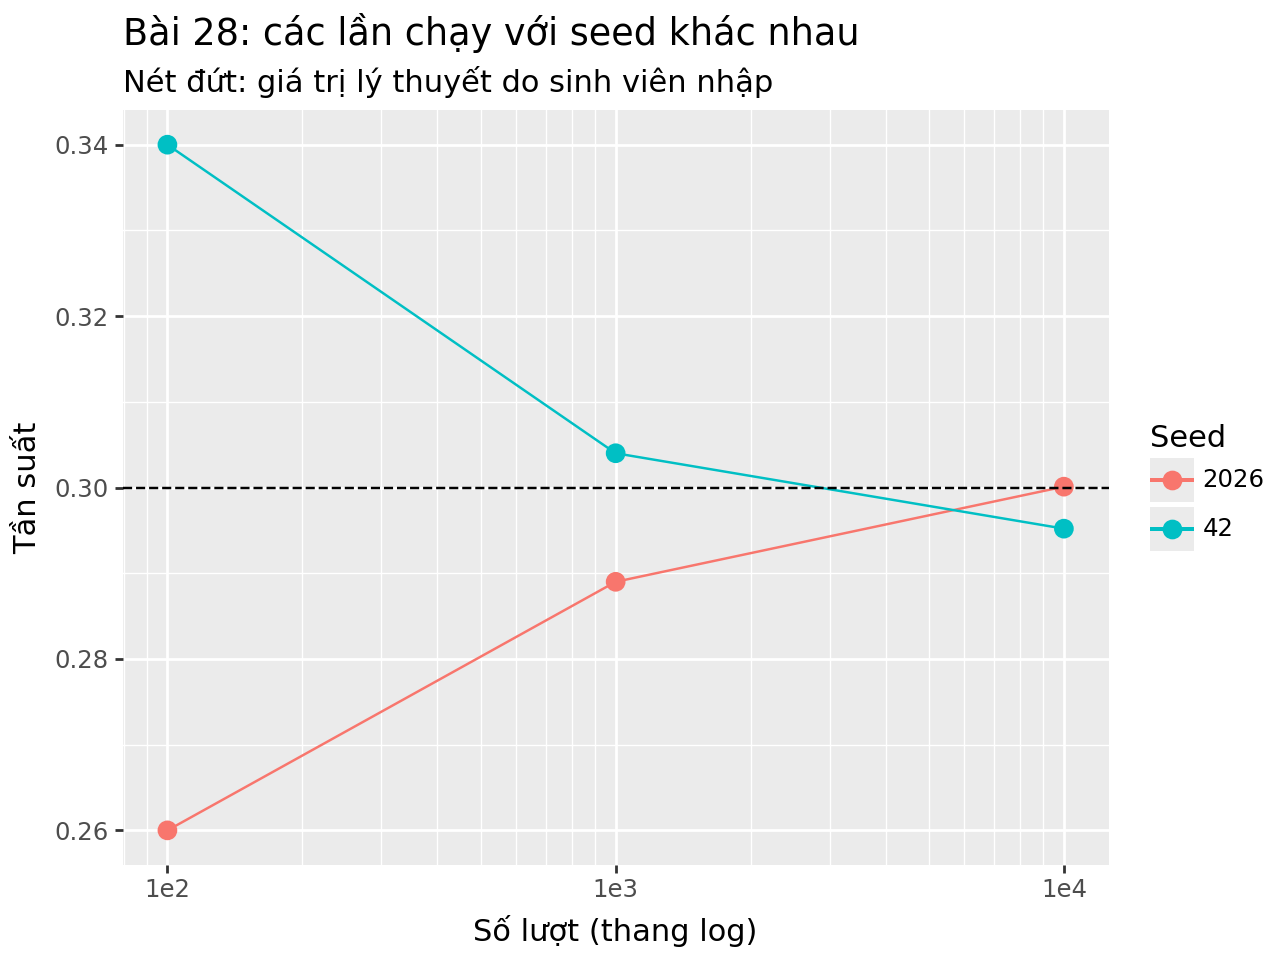

In [41]:
if table28 is None:
    print("Chưa vẽ: cần bảng đối chiếu của Bài 28.")
else:
    plot_data28 = table28.assign(seed_label=table28["seed"].astype(str))
    plot28 = (
        ggplot(plot_data28, aes(x="n_trials", y="frequency", group="seed_label", color="seed_label"))
        + geom_line() + geom_point(size=3)
        + geom_hline(yintercept=CONFIG28["p_theory"], linetype="dashed")
        + scale_x_log10(breaks=CONFIG28["sample_sizes"])
        + labs(title="Bài 28: các lần chạy với seed khác nhau",
               subtitle="Nét đứt: giá trị lý thuyết do sinh viên nhập",
               x="Số lượt (thang log)", y="Tần suất", color="Seed")
    )
    display(plot28)


**Bài làm 28b–d — sinh viên điền**

- Mỗi phần tử True trong dãy `flags` có nghĩa là: tương ứng với mỗi lần chọn được mã >= 35
- Vì sao `flags.mean()` bằng số lần xảy ra chia cỡ mẫu? Python coi True = 1, False = 0 $\to$ gọi mean() sẽ có tử số là số lần xảy ra biến cố A, mẫu số là cỡ mẫu.
- Ghi bảng kết quả với seed thứ nhất và seed thứ hai: Bảng kết quả chạy với seed = 2026 và seed = 42 được ghi ở trên.
- Sai lệch có buộc giảm sau mỗi lần tăng cỡ mẫu không? Dẫn chứng từ bảng của bạn: Sai lệch chưa chắc giảm sau mỗi lần tăng cỡ mẫu, có thể thấy ở seed 42, cỡ mẫu 1000 cho ra sai số nhỏ hơn cỡ mẫu 10000.
- Xác suất lý thuyết và tần suất mô phỏng khác nhau ở điểm nào? Xác suất lý thuyết dựa trên lập luận logic, tính toán. Tần suất mô phỏng chỉ kiểm chứng kết quả dựa trên việc lấy một cỡ mẫu đủ lớn.
- Khi dùng các tiền tố chung, ba tần suất có độc lập với nhau không? Vì sao? Không đọc lập với nhau,vì các kết quả của mẫu nhỏ hơn cũng nằm trong mẫu lớn hơn 


## Lưu kết quả để nộp

Ô sau chỉ xuất những bảng đã thực sự được tính. CSV và PNG là **kết quả do bạn tạo**, không phải dữ liệu bắt buộc phải tải trước. Chạy lại sẽ cập nhật tệp cùng tên trong thư mục `student`; sao chép kết quả cũ ra chỗ khác khi cần giữ nhiều lần chạy.


In [42]:
exported = []
if table27 is not None:
    table27.to_csv(OUTPUT_DIR / "exercise27_frequencies.csv", index=False, encoding="utf-8-sig")
    plot27.save(OUTPUT_DIR / "exercise27_frequencies.png", width=7.5, height=4.5, dpi=140, verbose=False)
    exported.append("Bài 27")
if table28 is not None:
    table28.to_csv(OUTPUT_DIR / "exercise28_summary.csv", index=False, encoding="utf-8-sig")
    plot28.save(OUTPUT_DIR / "exercise28_frequency.png", width=7.5, height=4.5, dpi=140, verbose=False)
    exported.append("Bài 28")

if exported:
    print("Đã xuất:", ", ".join(exported), "tại", OUTPUT_DIR.resolve())
else:
    print("Chưa xuất tệp: điền CONFIG27 và CONFIG28. Không tạo CSV rỗng.")

print("Trước khi nộp: Ctrl+S để lưu notebook và các phần giải thích đã viết.")


Đã xuất: Bài 27, Bài 28 tại C:\Users\admin\OneDrive\Documents\UET_2026_2027\MATH1052\MATH1052\PS05\PS05_AI_Student_A4_Notebooks\ps05_27_28_outputs\student
Trước khi nộp: Ctrl+S để lưu notebook và các phần giải thích đã viết.


## Tự kiểm tra trước khi nộp

☐ Bài 27 có lập luận về các cặp có thứ tự, không chỉ một hình. (ĐÃ LÀM)

☐ Không còn `None` trong hai ô cấu hình.  (ĐÃ LÀM)

☐ Bảng Bài 28 có đủ ba cỡ mẫu cho từng seed.  (ĐÃ CÓ)

☐ Các nhận xét do mình viết, dựa trên kết quả đã chạy. (ĐÃ LÀM)

☐ Đã lưu notebook cùng đầu ra; không chỉnh kết quả mô phỏng để “đẹp hơn”. (ĐÃ LƯU)
  
☐ Có ghi seed và không khẳng định mọi lần tăng cỡ mẫu đều làm sai lệch giảm. (ĐÃ LÀM)


## Tài liệu tra cú pháp

Nội dung bài tập theo **PS05-AI, bản A4 đã biên soạn, Bài 27–28**. Ví dụ học cú pháp được ghi riêng; không thay đổi yêu cầu của đề.

- [NumPy: Generator.integers](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.integers.html)
- [NumPy: Generator.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html)
- [plotnine: geom_col](https://plotnine.org/reference/geom_col.html)
- [VS Code: Jupyter Notebooks](https://code.visualstudio.com/docs/datascience/jupyter-notebooks)
